In [3]:

import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image, ImageFile

# Allow loading truncated images
ImageFile.LOAD_TRUNCATED_IMAGES = True

# Paths
folder = Path("print0")
csv_path = "caxton_dataset_filtered_no_outliers.csv"

# Load CSV
df = pd.read_csv(csv_path)

# Keep only print0 samples
df = df[df["print_id"] == 0].copy()

# Match images with CSV entries
df["img_path"] = df["img_path"].apply(
    lambda p: folder / Path(p).name
)

# Keep only existing images
df = df[df["img_path"].apply(lambda p: p.is_file())].copy()

# Load images as NumPy arrays
def load_image(path):
    try:
        with Image.open(path) as img:
            return np.array(img.convert("RGB"))
    except (OSError, ValueError):
        return None

df["image_array"] = df["img_path"].apply(load_image)

# Remove images that could not be loaded
df = df[df["image_array"].notna()].reset_index(drop=True)

# Move image column to the beginning
df.insert(0, "image", df.pop("image_array"))

print("Total samples:", len(df))
print("First image shape:", df.loc[0, "image"].shape)
print(df.head())



Total samples: 2710
First image shape: (720, 1280, 3)
                                               image             img_path  \
0  [[[252, 252, 252], [252, 252, 252], [252, 252,...   print0/image-6.jpg   
1  [[[252, 252, 252], [252, 252, 252], [252, 252,...   print0/image-7.jpg   
2  [[[252, 252, 252], [252, 252, 252], [252, 252,...   print0/image-8.jpg   
3  [[[252, 252, 252], [252, 252, 252], [252, 252,...   print0/image-9.jpg   
4  [[[252, 252, 252], [252, 252, 252], [252, 252,...  print0/image-10.jpg   

                timestamp  flow_rate  feed_rate  z_offset  target_hotend  \
0  2020-10-08T13:12:50-34        100        100       0.0          205.0   
1  2020-10-08T13:12:50-80        100        100       0.0          205.0   
2  2020-10-08T13:12:51-27        100        100       0.0          205.0   
3  2020-10-08T13:12:51-74        100        100       0.0          205.0   
4  2020-10-08T13:12:52-20        100        100       0.0          205.0   

   hotend    bed  nozzle_t

,Alloy ID,Alloy,Al,Co,Cr,Fe,Ni,Cu,Mn,Ti,...,Quenching,HPR,Microstructure_,Multiphase,IM_Structure,Microstructure,Phases,References,Unnamed: 51,Unnamed: 52
0,Alloy 0000,Al0.5NbTaTiV,0.111111,0.0,0.0,0.0,0.0,0.0,0.0,0.222222,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.1016/j.proeng.2012.03.043,NaN,NaN
1,Alloy 0001,Al0.75MoNbTiV,0.157895,0.0,0.0,0.0,0.0,0.0,0.0,0.210526,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.3390/e16020870,NaN,NaN
2,Alloy 0002,Al0.25MoNbTiV,0.058824,0.0,0.0,0.0,0.0,0.0,0.0,0.235294,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.3390/e16020870,NaN,NaN
3,Alloy 0003,Al0.25NbTaTiV,0.058824,0.0,0.0,0.0,0.0,0.0,0.0,0.235294,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.1016/j.proeng.2012.03.043,NaN,NaN
4,Alloy 0004,Al0.2MoTaTiV,0.047619,0.0,0.0,0.0,0.0,0.0,0.0,0.238095,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.4028/www.scientific.net/MSF.898.638,NaN,NaN


KeyError: 'image'

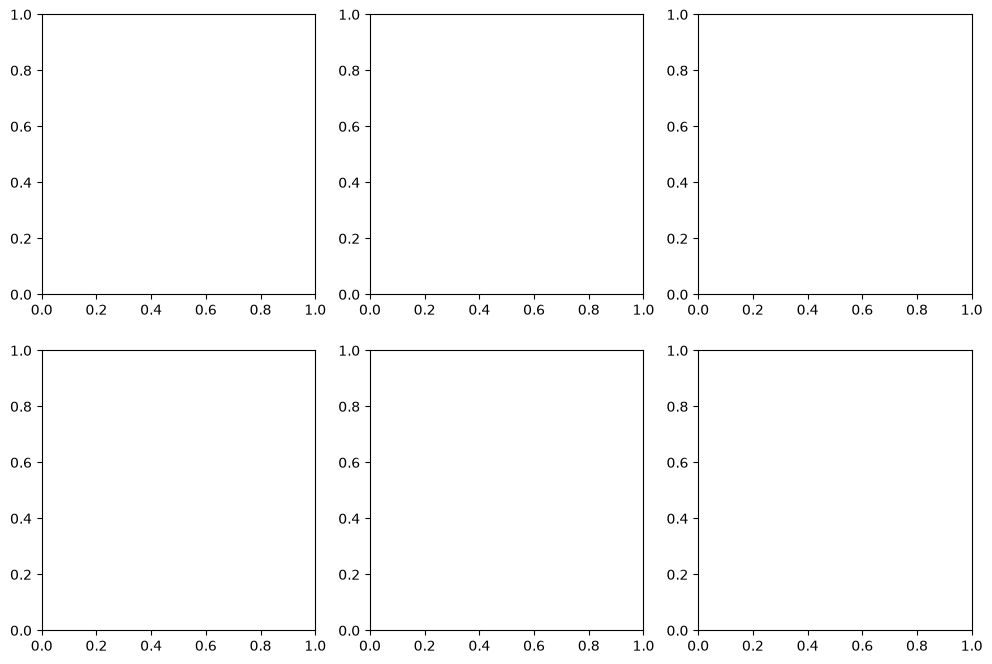

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(df.loc[i, "image"])
    ax.set_title(f"Image {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()